<div align="center">

**DS201.R11.1 - Deep Learning trong Khoa học Dữ liệu**

**Báo cáo Lab 02:**

**MẠNG NEURAL TÍCH CHẬP (CONVOLUTIONAL NEURAL NETWORK)**

</div>

**Họ và tên:** Huỳnh Lâm Bảo Khang

**MSSV:** 24520738

**Lớp:** DS201.R11.1

**Bộ dữ liệu sử dụng duy nhất cho cả 4 bài:** [VinaFood21 dataset](https://arxiv.org/abs/2108.02929)
- **Link download:** https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link

---

#### Tổ chức mã nguồn
Có 4 module .py chính:

```text
Lab02/
├── data.py # MEAN/STD ImageNet, build_transforms (tách riêng train và val/test), DataLoader cùng seed=42
├── models.py # LeNet5, InceptionBlock, GoogLeNetMini, BasicBlock, ResNet18, PretrainedResnet, n_params
├── engine.py # train_one_epoch, evaluate (model.eval + torch.no_grad), fit (lưu best val macro-F1)
├── utils.py # set_seed, vẽ biểu đồ Loss/Acc/F1, Confusion Matrix 21x21, evaluate_test, bảng so sánh
└── assignments_.ipynb
```

#### Cấu hình chung của 4 bài

- Bài 1 - LeNet-5 (7 tầng, ReLU, 21 lớp):
  - Resize: 64 x 64
  - Optimizer: Adam (lr=1e-3)
  - Augmentation (chỉ tập train): flip
  - Yêu cầu thực nghiệm riêng: Chạy AvgPool2d(2,2) sau đó chạy MaxPool2d(2,2) để so sánh; đối chiếu 339.421 tham số; layer cuối dùng nn.Linear(84,21)
- Bài 2 - GoogLeNet rút gọn (4 InceptionBlock + GAP):
  - Resize: 64 x 64
  - Optimizer: Adam (lr=1e-3)
  - Augmentation (chỉ tập train): flip
  - Yêu cầu thực nghiệm riêng: Dùng AdaptiveAvgPool2d(1) thay Flatten; đối chiếu số channel từng blocks; so sánh với bài 1
- Bài 3 - ResNet-18 ([2,2,2,2] BasicBlock):
  - Resize: 96 x 96
  - Optimizer: Adam (lr=1e-3)
  - Augmentation (chỉ tập train): chạy 2 lần: ko & có augment
  - Yêu cầu thực nghiệm riêng: Xác nhận 11.187.285 tham số; xác định epoch tách đường train/val loss; đo độ chênh lệch macro-F1
- Bài 4 - ResNet-50 pre-train (microsoft/resnet-50):
  - Resize: 224 x 224
  - Optimizer: Adam (1e-3/1e-4)
  - Augmentation (chỉ tập train): như bài 3
  - Yêu cầu thực nghiệm riêng: Chạy cả 2 chế độ: Feature Extraction (lr-1e-3) & Finetuning (lr=1e-4); bảng tổng kế 4 model

> **Nguyên tắc xuyên suốt cả 4 bài:**
> 1. Cố định SEED = 42 để cả 4 bài dùng cùng một phép chia train/val/test
> 2. Chỉ augment tập train, tập val & test dùng bộ eval_tf riêng biệt; luôn gọi model.eval() và @torch.no_grad() khi đánh giá
> 3. Độ đo chính là macro-F1 (chọn checkpoint best.pt theo val macro-F1 cao nhất), báo cáo kèm Accuracy, Precision, Recall, F1 từng lớp và Confusion Matrix 21×21

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import torch
import torch.nn as nn

#Tu dong clone repo tu GitHub neu mo notebook truc tiep tren Google Colab
REPO_URL = "https://github.com/khanghl/DS201-Lab02-CNN.git"
REPO_DIR = Path("/content/DS201-Lab02-CNN")

if "google.colab" in sys.modules and not Path("models.py").is_file():
    if not (REPO_DIR / "models.py").is_file():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
    os.chdir(REPO_DIR)

#Tu dong nhan dien thu muc chua cac file .py
for candidate in [Path.cwd(), Path.cwd() / "Lab02", REPO_DIR]:
    if (candidate / "models.py").is_file():
        if str(candidate.resolve()) not in sys.path:
            sys.path.insert(0, str(candidate.resolve()))
        break

from data import (
    MEAN,
    STD,
    build_test_loader,
    build_train_val_loaders,
    ensure_vinafood21,
    get_class_distribution,
)
from engine import evaluate, fit, train_one_epoch
from models import (
    BasicBlock,
    GoogLeNetMini,
    InceptionBlock,
    LeNet5,
    PretrainedResnet,
    ResNet18,
    n_params,
    n_trainable_params,
)
from utils import (
    evaluate_test,
    plot_class_distribution,
    plot_history,
    plot_model_comparison,
    print_comparison_table,
    set_seed,
)

#Tham so dung chung cho ca 4 bai (dong bo voi lenet_project/train.py)
SEED = 42
BATCH_SIZE = 32
VAL_RATIO = 0.10
EPOCHS = 20

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results = {} #Luu kq danh gia tap test cua toan bo thuc nghiem

print(f"Thu muc hien tai : {Path.cwd()}")
print(f"PyTorch          : {torch.__version__}")
print(f"Device           : {device}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else " (CPU)"))
print(f"Cau hinh         : SEED={SEED} | BATCH_SIZE={BATCH_SIZE} | VAL_RATIO={VAL_RATIO} | EPOCHS={EPOCHS}")

Thu muc hien tai : /content/DS201-Lab02-CNN
PyTorch          : 2.11.0+cpu
Device           : cpu (CPU)
Cau hinh         : SEED=42 | BATCH_SIZE=32 | VAL_RATIO=0.1 | EPOCHS=20


#### Khảo sát bộ dữ liệu VinaFood21 & Chia dữ liệu

- Thư mục VinaFood21/ có sẵn hai tập train/ (10,044 ảnh) và test/ (6,682 ảnh), chưa tách riêng thư mục val/
- Trong data.py, hàm build_train_val_loaders khởi tạo 2 đối tượng ImageFolder độc lập cùng trỏ vào VinaFood21/train (full_train gắn train_tf, full_eval gắn eval_tf) rồi tách 10% làm val bằng torch.Generator().manual_seed(42). Nhờ đó:
  - Cả 4 bài đều chạy trên đúng cùng một tập mẫu train (9,040 ảnh), val (1,004 ảnh) và test (6,682 ảnh)
  - Tập val hoàn toàn không bị áp dụng phép biến đổi ngẫu nhiên của tập train
- Do dữ liệu thu thập thực tế có sự mất cân bằng số lượng ảnh giữa các lớp, độ đo Accuracy dễ thiên lệch về các lớp nhiều mẫu; vì vậy macro-F1 (trung bình không trọng số F1 của 21 lớp) được chọn làm độ đo chính

Thu muc du lieu: /content/DS201-Lab02-CNN/VinaFood21
So lop mon an: 21 lop (theo thu tu bang chu cai cua ImageFolder)
Danh sach lop: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']
Tong anh train/: 10,044 anh -> tach Train: 9,040 | Val: 1,004
Tong anh test/  : 6,682 anh
Lop nhieu nhat  : banh-hoi (910 anh train) | Lop it nhat: bap-nuong (215 anh train) -> Ti le chenh lech 4.23 lan


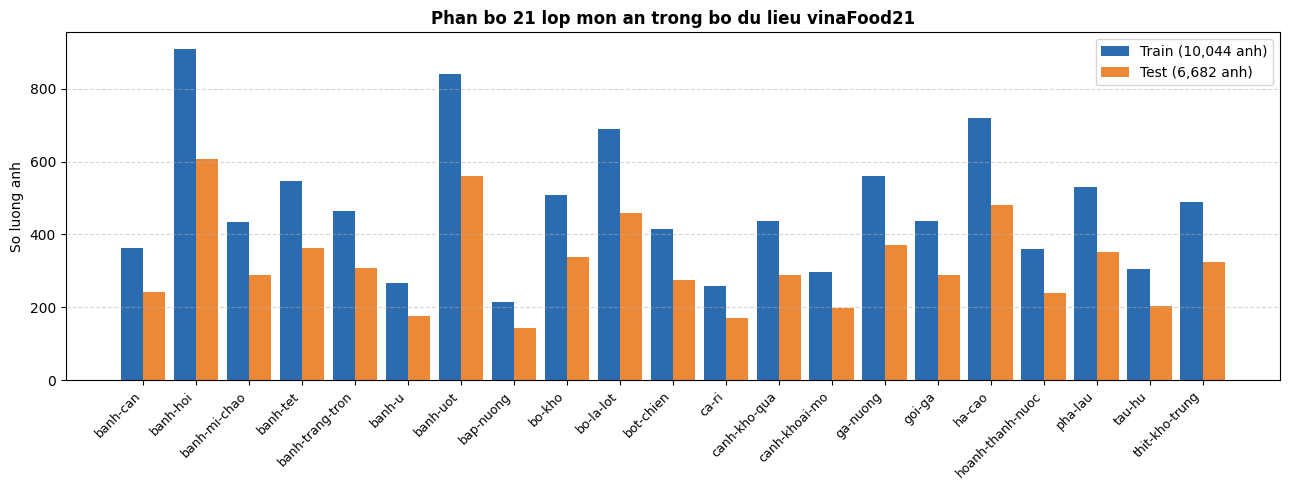

In [2]:
DATA_ROOT = ensure_vinafood21("VinaFood21")
classes, train_counts, test_counts = get_class_distribution(DATA_ROOT)

min_idx = min(range(len(classes)), key=lambda i: train_counts[i])
max_idx = max(range(len(classes)), key=lambda i: train_counts[i])

print(f"Thu muc du lieu: {DATA_ROOT.resolve()}")
print(f"So lop mon an: {len(classes)} lop (theo thu tu bang chu cai cua ImageFolder)")
print(f"Danh sach lop: {classes}")
print(f"Tong anh train/: {sum(train_counts):,} anh -> tach Train: {sum(train_counts) - int(sum(train_counts)*VAL_RATIO):,} | Val: {int(sum(train_counts)*VAL_RATIO):,}")
print(f"Tong anh test/  : {sum(test_counts):,} anh")
print(f"Lop nhieu nhat  : {classes[max_idx]} ({train_counts[max_idx]} anh train) | "
      f"Lop it nhat: {classes[min_idx]} ({train_counts[min_idx]} anh train) "
      f"-> Ti le chenh lech {train_counts[max_idx] / train_counts[min_idx]:.2f} lan")

plot_class_distribution(classes, train_counts, test_counts)

### Bài 1: LeNet-5 điều chỉnh trên VinaFood21

#### Kiến trúc và bảng tính tham số lý thuyết (Ảnh màu 64×64×3, 21 lớp)

Khác với LeNet-5 năm 1998 trên ảnh xám 32×32×1 (tanh, 10 lớp), phiên bản điều chỉnh cho VinaFood21 trong models.LeNet5 giữ nguyên bố cục 7 tầng nhưng nhận đầu vào RGB 64×64×3, dùng hàm kích hoạt ReLU và đầu ra 21 logits:

| Layer | Phép biến đổi | Output shape (H × W × C) | Công thức tính tham số | Số tham số |
| :--- | :--- | :---: | :--- | ---: |
| **C1** | Conv2d(3, 6, kernel_size=5, stride=1, padding=0) + ReLU | 60 × 60 × 6 | $(5 \times 5 \times 3 + 1) \times 6$ | 456 |
| **S2** | AvgPool2d(2, 2) *(hoặc MaxPool2d(2, 2))* | 30 × 30 × 6 | Không có tham số học | 0 |
| **C3** | Conv2d(6, 16, kernel_size=5, stride=1, padding=0) + ReLU | 26 × 26 × 16 | $(5 \times 5 \times 6 + 1) \times 16$ | 2,416 |
| **S4** | AvgPool2d(2, 2) *(hoặc MaxPool2d(2, 2))* $\rightarrow$ Flatten | 13 × 13 × 16 = 2,704 | Không có tham số học | 0 |
| **F5** | Linear(2704, 120) + ReLU | 120 | $2,704 \times 120 + 120$ | 324,600 |
| **F6** | Linear(120, 84) + ReLU | 84 | $120 \times 84 + 84$ | 10,164 |
| **OUT** | Linear(84, 21) *(logits thô đưa vào CrossEntropyLoss)* | 21 | $84 \times 21 + 21$ | 1,785 |
| **TỔNG** | **7 tầng (2 Conv + 2 Pool + 3 Linear)** | **21 logits** | $456 + 2,416 + 324,600 + 10,164 + 1,785$ | **339,421** |

In [3]:
#Khoi tao DataLoader 64x64 dung chung cho Bai 1 va Bai 2 (augment lat ngang)
train_dl_64, val_dl_64, _ = build_train_val_loaders(
    DATA_ROOT, img_size=64, batch_size=BATCH_SIZE,
    val_ratio=VAL_RATIO, augment="flip", seed=SEED,
)
test_dl_64, test_classes = build_test_loader(DATA_ROOT, img_size=64, batch_size=BATCH_SIZE)
assert test_classes == classes, "Thu tu lop giua train va test khong khop!"

#Kiem tra shape tren 1 batch thuc te va doi chieu so tham so voi ly thuyet 339,421
xb_sample, yb_sample = next(iter(train_dl_64))
lenet_avg = LeNet5(in_ch=3, img=64, num_classes=len(classes), pool_type="avg")
lenet_max = LeNet5(in_ch=3, img=64, num_classes=len(classes), pool_type="max")

with torch.no_grad():
    logits_sample = lenet_avg(xb_sample)

print(f"DataLoader 64x64: train={len(train_dl_64.dataset):,} | val={len(val_dl_64.dataset):,} | test={len(test_dl_64.dataset):,}")
print(f"Batch input: {tuple(xb_sample.shape)} -> Output logits: {tuple(logits_sample.shape)}")
print("\nChi tiet tham so tung tang cua LeNet-5:")
for name, layer in [("C1", lenet_avg.c1), ("S2", lenet_avg.s2), ("C3", lenet_avg.c3),
                    ("S4", lenet_avg.s4), ("F5", lenet_avg.f5), ("F6", lenet_avg.f6), ("OUT", lenet_avg.out)]:
    print(f"  {name:<4} : {n_params(layer):>10,} tham so")

print(f"Tong tham so LeNet-5 (AvgPool) : {n_params(lenet_avg):,}")
print(f"Tong tham so LeNet-5 (MaxPool) : {n_params(lenet_max):,}")
assert n_params(lenet_avg) == 339_421 and n_params(lenet_max) == 339_421
print("-> Xac nhan khop chinh xac 339,421 tham so theo de bai!")

DataLoader 64x64: train=9,040 | val=1,004 | test=6,682
Batch input: (32, 3, 64, 64) -> Output logits: (32, 21)

Chi tiet tham so tung tang cua LeNet-5:
  C1   :        456 tham so
  S2   :          0 tham so
  C3   :      2,416 tham so
  S4   :          0 tham so
  F5   :    324,600 tham so
  F6   :     10,164 tham so
  OUT  :      1,785 tham so
Tong tham so LeNet-5 (AvgPool) : 339,421
Tong tham so LeNet-5 (MaxPool) : 339,421
-> Xac nhan khop chinh xac 339,421 tham so theo de bai!


Bai 1a - Huan luyen LeNet-5 (AvgPool2d, 64x64, Adam lr=1e-3)
epoch  1/20  train 2.7435/0.1692   val 2.5624/0.2072  F1 0.1373   (171.6s)  *
epoch  2/20  train 2.4809/0.2410   val 2.4005/0.2610  F1 0.2041   (141.7s)  *
epoch  3/20  train 2.3751/0.2711   val 2.3340/0.2779  F1 0.2277   (141.4s)  *
epoch  4/20  train 2.2846/0.3015   val 2.3167/0.2779  F1 0.2344   (142.2s)  *
epoch  5/20  train 2.1915/0.3192   val 2.2388/0.3137  F1 0.2651   (142.4s)  *
epoch  6/20  train 2.0938/0.3543   val 2.2663/0.3147  F1 0.2689   (143.2s)  *
epoch  7/20  train 2.0127/0.3769   val 2.2478/0.3207  F1 0.2882   (143.4s)  *
epoch  8/20  train 1.9233/0.3968   val 2.2439/0.3227  F1 0.2758   (142.3s)
epoch  9/20  train 1.8416/0.4250   val 2.2764/0.3337  F1 0.2869   (141.7s)
epoch 10/20  train 1.7657/0.4427   val 2.2684/0.3287  F1 0.3003   (141.4s)  *
epoch 11/20  train 1.6559/0.4744   val 2.3456/0.3347  F1 0.3158   (141.6s)  *
epoch 12/20  train 1.5858/0.5055   val 2.4009/0.3108  F1 0.2823   (142.2s)
epoch 13/20 

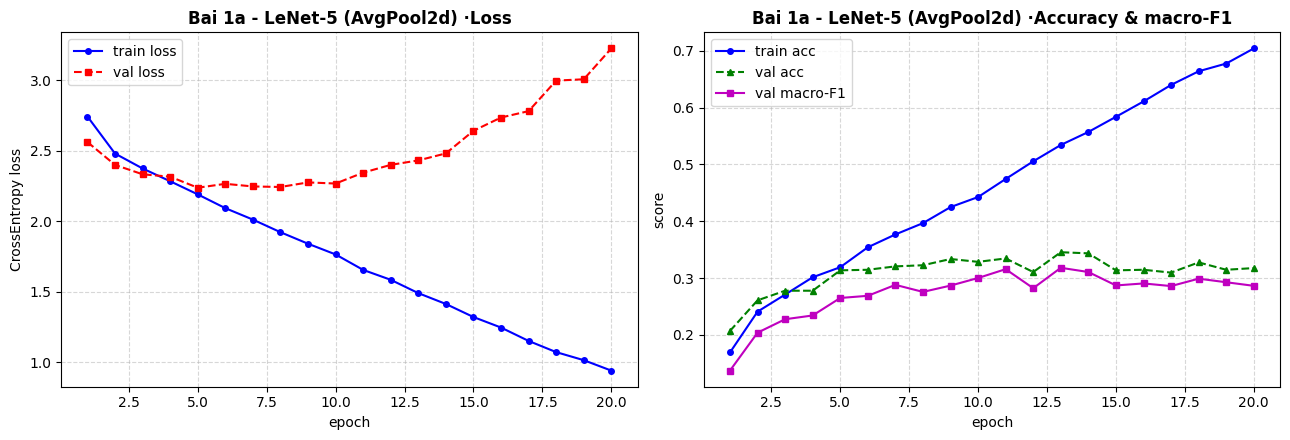

KET QUA TAP TEST LeNet-5 (AvgPool):
    - Kich thuoc anh: 64x64
    - Tong so tham so: 339,421 (cap nhat: 339,421)
 Thoi gian / epoch : 143.79s
    - Test Loss         : 2.7421
    - Accuracy          : 0.2812 (28.12%)
    - Precision (macro) : 0.2643
    - Recall (macro)    : 0.2716
    - macro-F1 (chinh)  : 0.2597

Bang Precision, Recall, F1 tung lop (21 lop vinaFood21)
                  precision    recall  f1-score   support

        banh-can     0.1471    0.1245    0.1348       241
        banh-hoi     0.3278    0.3888    0.3557       607
    banh-mi-chao     0.2521    0.3114    0.2786       289
        banh-tet     0.2789    0.1456    0.1913       364
 banh-trang-tron     0.1418    0.1230    0.1317       309
          banh-u     0.2170    0.1307    0.1631       176
        banh-uot     0.2822    0.2232    0.2493       560
       bap-nuong     0.1533    0.1469    0.1500       143
          bo-kho     0.2203    0.3846    0.2802       338
       bo-la-lot     0.4028    0.6376    0.4

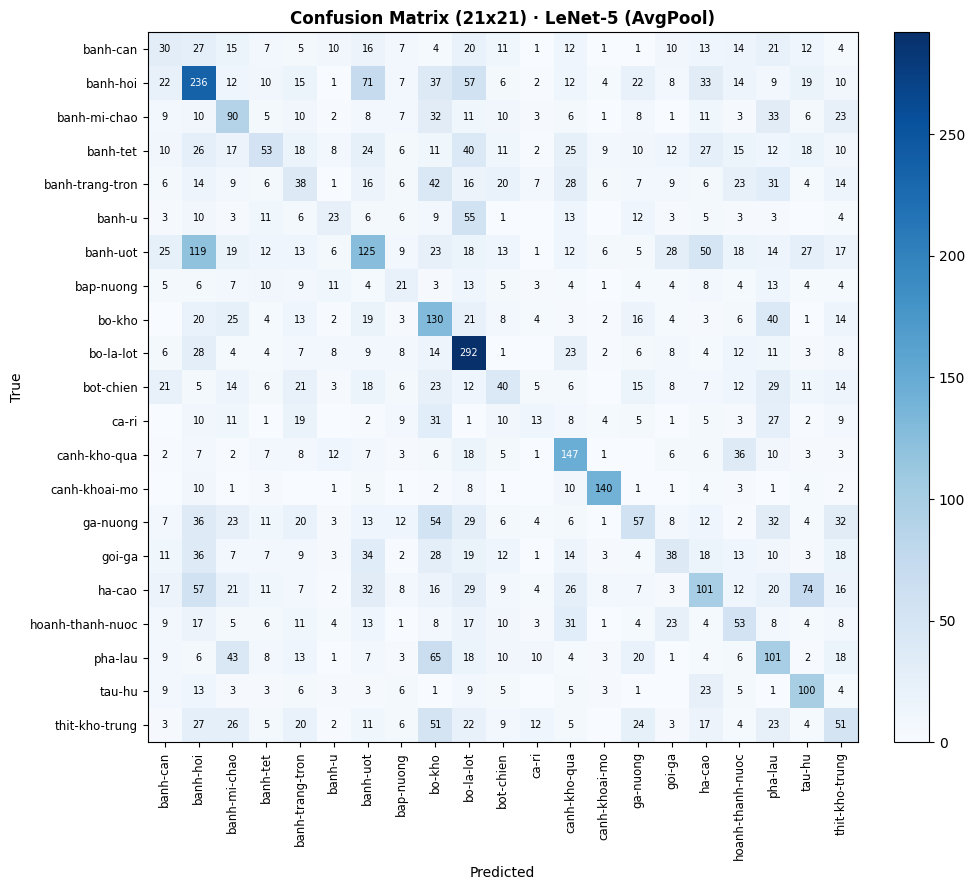

In [4]:
#Bai 1a: Huan luyen va danh gia LeNet-5 ban goc voi AvgPool2d(2, 2)
set_seed(SEED)
lenet_avg = LeNet5(in_ch=3, img=64, num_classes=len(classes), pool_type="avg")

print("Bai 1a - Huan luyen LeNet-5 (AvgPool2d, 64x64, Adam lr=1e-3)")
hist_lenet_avg, info_lenet_avg = fit(
    model=lenet_avg,
    train_dl=train_dl_64,
    val_dl=val_dl_64,
    epochs=EPOCHS,
    lr=1e-3,
    device=device,
    out_dir="outputs/bai1_lenet_avg",
    classes=classes,
    img_size=64,
)

plot_history(
    hist_lenet_avg,
    title="Bai 1a - LeNet-5 (AvgPool2d)",
    save_path="outputs/bai1_lenet_avg/loss_curve.png",
)

results["lenet_avg"] = evaluate_test(
    model=lenet_avg,
    test_dl=test_dl_64,
    classes=classes,
    device=device,
    model_name="LeNet-5 (AvgPool)",
    img_size=64,
    sec_per_epoch=info_lenet_avg["sec_per_epoch"],
    out_dir="outputs/bai1_lenet_avg",
)

Bai 1b - Huan luyen LeNet-5 (MaxPool2d, 64x64, Adam lr=1e-3)
epoch  1/20  train 2.7872/0.1583   val 2.6250/0.2122  F1 0.1166   (141.1s)  *
epoch  2/20  train 2.5412/0.2267   val 2.3848/0.2639  F1 0.1998   (141.1s)  *
epoch  3/20  train 2.3644/0.2789   val 2.3348/0.2809  F1 0.2228   (141.4s)  *
epoch  4/20  train 2.2421/0.3169   val 2.2480/0.2978  F1 0.2471   (141.6s)  *
epoch  5/20  train 2.1368/0.3439   val 2.1698/0.3376  F1 0.2903   (140.5s)  *
epoch  6/20  train 2.0347/0.3716   val 2.1643/0.3386  F1 0.3090   (141.3s)  *
epoch  7/20  train 1.9199/0.4065   val 2.1220/0.3546  F1 0.3210   (141.4s)  *
epoch  8/20  train 1.8117/0.4393   val 2.2507/0.3396  F1 0.2996   (140.0s)
epoch  9/20  train 1.7183/0.4668   val 2.1484/0.3576  F1 0.3251   (140.4s)  *
epoch 10/20  train 1.6042/0.5065   val 2.2274/0.3606  F1 0.3320   (141.3s)  *
epoch 11/20  train 1.5246/0.5291   val 2.1894/0.3466  F1 0.3259   (140.5s)
epoch 12/20  train 1.4176/0.5615   val 2.2860/0.3436  F1 0.3226   (141.1s)
epoch 13/20 

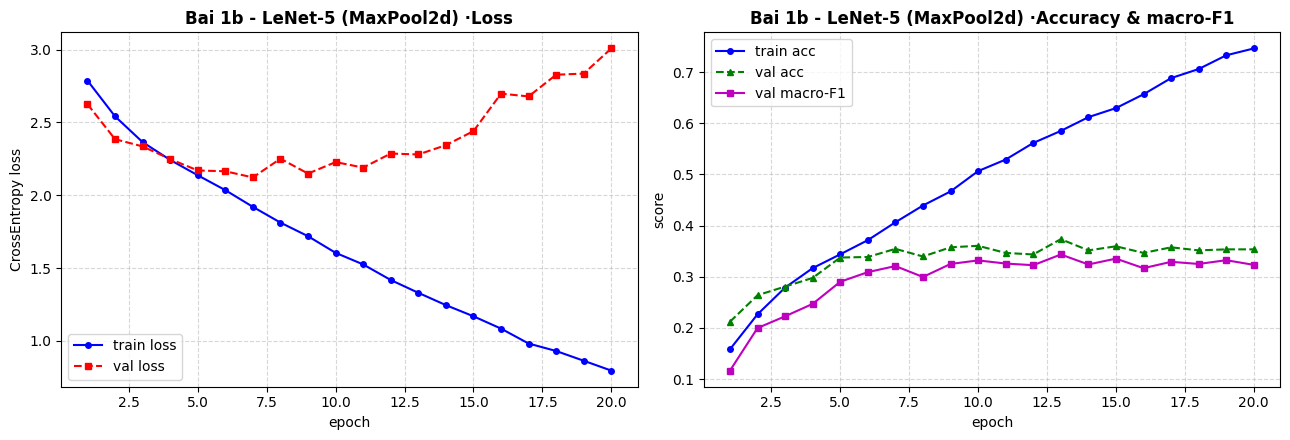

KET QUA TAP TEST LeNet-5 (MaxPool):
    - Kich thuoc anh: 64x64
    - Tong so tham so: 339,421 (cap nhat: 339,421)
 Thoi gian / epoch : 140.69s
    - Test Loss         : 2.5607
    - Accuracy          : 0.3114 (31.14%)
    - Precision (macro) : 0.3029
    - Recall (macro)    : 0.3033
    - macro-F1 (chinh)  : 0.2989

Bang Precision, Recall, F1 tung lop (21 lop vinaFood21)
                  precision    recall  f1-score   support

        banh-can     0.2690    0.1618    0.2021       241
        banh-hoi     0.3490    0.3789    0.3633       607
    banh-mi-chao     0.2808    0.2837    0.2823       289
        banh-tet     0.2343    0.3187    0.2701       364
 banh-trang-tron     0.2105    0.1553    0.1788       309
          banh-u     0.2000    0.1989    0.1994       176
        banh-uot     0.2762    0.1929    0.2271       560
       bap-nuong     0.1203    0.1119    0.1159       143
          bo-kho     0.2871    0.4467    0.3495       338
       bo-la-lot     0.4443    0.5917    0.5

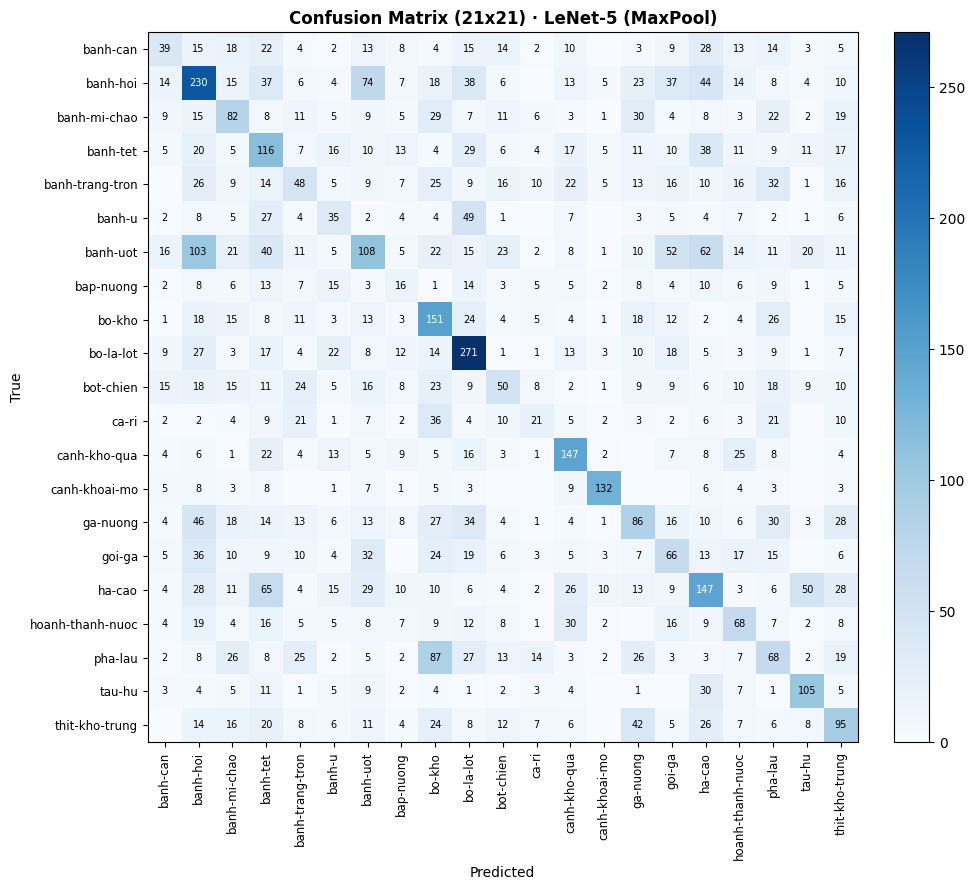

=== So sanh bai 1: AvgPool2d vs MaxPool2d tren LeNet-5 ===
Mo hiinh                         |  Resize   |      Tham so |     s/ep |  Accuracy | Precision |   Recall |  macro-F1
---------------------------------------------------------------------------------------------------------------------
LeNet-5 (AvgPool)                |   64x64   |      339,421 |  143.79s |    0.2812 |    0.2643 |   0.2716 |    0.2597
LeNet-5 (MaxPool)                |   64x64   |      339,421 |  140.69s |    0.3114 |    0.3029 |   0.3033 |    0.2989

Chenh lech macro-F1 (MaxPool - AvgPool): +0.0392


In [5]:
#Bai 1b: Thu lai LeNet-5 voi MaxPool2d(2, 2) (giu nguyen toan bo dieu kien khac de so sanh)
set_seed(SEED)
lenet_max = LeNet5(in_ch=3, img=64, num_classes=len(classes), pool_type="max")

print("Bai 1b - Huan luyen LeNet-5 (MaxPool2d, 64x64, Adam lr=1e-3)")
hist_lenet_max, info_lenet_max = fit(
    model=lenet_max,
    train_dl=train_dl_64,
    val_dl=val_dl_64,
    epochs=EPOCHS,
    lr=1e-3,
    device=device,
    out_dir="outputs/bai1_lenet_max",
    classes=classes,
    img_size=64,
)

plot_history(
    hist_lenet_max,
    title="Bai 1b - LeNet-5 (MaxPool2d)",
    save_path="outputs/bai1_lenet_max/loss_curve.png",
)


results["lenet_max"] = evaluate_test(
    model=lenet_max,
    test_dl=test_dl_64,
    classes=classes,
    device=device,
    model_name="LeNet-5 (MaxPool)",
    img_size=64,
    sec_per_epoch=info_lenet_max["sec_per_epoch"],
    out_dir="outputs/bai1_lenet_max",
)

#Doi chieu chenh lech macro-F1 giua AvgPool2d va MaxPool2d
print_comparison_table(
    [results["lenet_avg"], results["lenet_max"]],
    title="So sanh bai 1: AvgPool2d vs MaxPool2d tren LeNet-5",
)
diff_pool_f1 = results["lenet_max"]["macro_f1"] - results["lenet_avg"]["macro_f1"]
print(f"Chenh lech macro-F1 (MaxPool - AvgPool): {diff_pool_f1:+.4f}")

#### Nhận xét (LeNet-5 trên VinaFood21)

- **Phân bố tham số:** Hai lớp tích chập C1 và C3 chỉ có 456 + 2,416 = 2,872 tham số (**0.85%** tổng mạng), trong khi ba lớp kết nối đầy đủ sau Flatten chiếm tới **99.15%** (riêng F5 chiếm 324,600 / 339,421 = 95.63%). Điều này cho thấy nhược điểm lớn của Flatten khi kích thước ảnh tăng từ 32×32 lên 64×64: phần trích xuất đặc trưng quá mỏng nhưng phần phân lớp lại phình to, dễ ghi nhớ nhiễu tập train
- **Ảnh hưởng của MaxPool2d so với AvgPool2d:** AvgPool2d lấy trung bình vùng $2 \times 2$ nên làm mờ biên cạnh và màu sắc cục bộ của món ăn; ngược lại MaxPool2d giữ lại đáp ứng kích hoạt cực đại đặc trưng nhất trong từng vùng (như kết cấu sợi bún, màu nước dùng, miếng chả/thịt), giúp cải thiện khả năng phân biệt giữa 21 món ăn mà không phát sinh thêm bất kỳ tham số nào

---
### Bài 2 · GoogLeNet rút gọn trên VinaFood21

#### Kiến trúc InceptionBlock và GoogLeNetMini (64×64×3, 4 khối Inception + GAP)

Mô hình GoogLeNetMini trong models.py được thiết kế thống nhất ở kích thước ảnh 64×64 như Bài 1, gồm lớp stem và **4 khối InceptionBlock** (không dùng auxiliary classifier), kết thúc bằng **nn.AdaptiveAvgPool2d(1)** thay cho nn.Flatten():

- Mỗi InceptionBlock(in_ch, f1, f3r, f3, f5r, f5, fp) xử lý song song 4 nhánh cùng giữ nguyên chiều không gian $H \times W$ rồi nối theo chiều kênh torch.cat([b1, b2, b3, b4], dim=1):
  - Nhánh 1: Conv 1×1 (f1)
  - Nhánh 2: Conv 1×1 (f3r) -> Conv 3×3 (f3, padding=1)
  - Nhánh 3: Conv 1×1 (f5r) -> Conv 5×5 (f5, padding=2)
  - Nhánh 4: MaxPool 3×3 (stride=1, padding=1) -> Conv 1×1 (fp)
  - Số channel đầu ra lý thuyết: $C_{\text{out}} = f_1 + f_3 + f_5 + f_p$ *(hai thông số bottleneck $f_{3r}, f_{5r}$ là kênh trung gian giảm chi phí tính toán, không cộng vào output)*

| Khối | Cấu hình (f1, f3r, f3, f5r, f5, fp) | Tính channel output ($f_1 + f_3 + f_5 + f_p$) | Output shape [N, C, H, W] | Tham số |
| :--- | :---: | :---: | :---: | ---: |
| **stem** | Conv 3×3 (3→32, pad=1) + MaxPool 2×2 | 32 | [N, 32, 32, 32] | 896 |
| **inc1** | (16, 16, 24, 4, 8, 8) | $16 + 24 + 8 + 8 = \mathbf{56}$ | [N, 56, 32, 32] | 6,076 |
| **inc2** | (32, 32, 48, 8, 16, 16) | $32 + 48 + 16 + 16 = \mathbf{112}$ | [N, 112, 32, 32] | 22,104 |
| **pool1** | MaxPool2d(2, 2) | 112 | [N, 112, 16, 16] | 0 |
| **inc3** | (64, 48, 96, 16, 32, 32) | $64 + 96 + 32 + 32 = \mathbf{224}$ | [N, 224, 16, 16] | 72,944 |
| **pool2** | MaxPool2d(2, 2) | 224 | [N, 224, 8, 8] | 0 |
| **inc4** | (64, 64, 128, 16, 32, 32) | $64 + 128 + 32 + 32 = \mathbf{256}$ | [N, 256, 8, 8] | 125,488 |
| **gap + fc** | AdaptiveAvgPool2d(1) $\rightarrow$ Linear(256, 21) | 256 -> 21 | [N, 21] | 5,397 |
| **TỔNG** | **Stem + 4 InceptionBlock + GAP + Linear** | **21 logits** | — | **232,905** |

In [6]:
#Doi chieu so channel output cua tung InceptionBlock giua ly thuyet va code thuc te
googlenet_mini = GoogLeNetMini(in_ch=3, num_classes=len(classes))
dummy_64 = torch.zeros(2, 3, 64, 64)

print(f"{'Khoi':<8} | {'C_out ly thuyet':>16} | {'Shape thuc te trong code':<24} | {'Doi chieu':^10}")
print("-" * 68)
for block_name, expected_ch, actual_shape in googlenet_mini.inspect_blocks(dummy_64):
    actual_ch = actual_shape[1]
    assert expected_ch == actual_ch, f"Lech so channel tai {block_name}: {expected_ch} != {actual_ch}"
    print(f"{block_name:<8} | {expected_ch:>16} | {str(actual_shape):<24} | {'Khop':^10}")

print(f"\nTong tham so GoogLeNetMini: {n_params(googlenet_mini):,} tham so")
print(f"So voi LeNet-5 (Bai 1): giam {339_421 - n_params(googlenet_mini):,} tham so "
      f"({(1 - n_params(googlenet_mini) / 339_421) * 100:.1f}% nhe hon du mang sau hon nhieu)")

Khoi     |  C_out ly thuyet | Shape thuc te trong code | Doi chieu 
--------------------------------------------------------------------
stem     |               32 | (2, 32, 32, 32)          |    Khop   
inc1     |               56 | (2, 56, 32, 32)          |    Khop   
inc2     |              112 | (2, 112, 32, 32)         |    Khop   
pool1    |              112 | (2, 112, 16, 16)         |    Khop   
inc3     |              224 | (2, 224, 16, 16)         |    Khop   
pool2    |              224 | (2, 224, 8, 8)           |    Khop   
inc4     |              256 | (2, 256, 8, 8)           |    Khop   
gap      |              256 | (2, 256)                 |    Khop   
fc       |               21 | (2, 21)                  |    Khop   

Tong tham so GoogLeNetMini: 232,905 tham so
So voi LeNet-5 (Bai 1): giam 106,516 tham so (31.4% nhe hon du mang sau hon nhieu)


Bai 2 -Huan luyen GoogLeNet rut gon (64x64, Adam lr=1e-3)
epoch  1/20  train 2.9262/0.0999   val 2.7370/0.1235  F1 0.0545   (283.1s)  *
epoch  2/20  train 2.6016/0.1936   val 2.5376/0.2281  F1 0.1678   (284.5s)  *
epoch  3/20  train 2.4519/0.2410   val 2.3040/0.2669  F1 0.1848   (285.6s)  *
epoch  4/20  train 2.3358/0.2671   val 2.2138/0.3137  F1 0.2689   (287.5s)  *
epoch  5/20  train 2.2508/0.2988   val 2.1396/0.3177  F1 0.2717   (279.7s)  *
epoch  6/20  train 2.1499/0.3314   val 2.1371/0.3486  F1 0.3054   (281.1s)  *
epoch  7/20  train 2.0651/0.3564   val 1.9475/0.3954  F1 0.3492   (282.9s)  *
epoch  8/20  train 1.9837/0.3876   val 1.8915/0.4273  F1 0.3722   (285.0s)  *
epoch  9/20  train 1.9292/0.3918   val 1.8372/0.4293  F1 0.3794   (286.8s)  *
epoch 10/20  train 1.8657/0.4160   val 1.8122/0.4303  F1 0.3757   (286.9s)
epoch 11/20  train 1.7877/0.4385   val 1.8210/0.4173  F1 0.3720   (284.7s)
epoch 12/20  train 1.7613/0.4490   val 1.7651/0.4512  F1 0.3966   (284.8s)  *
epoch 13/20 

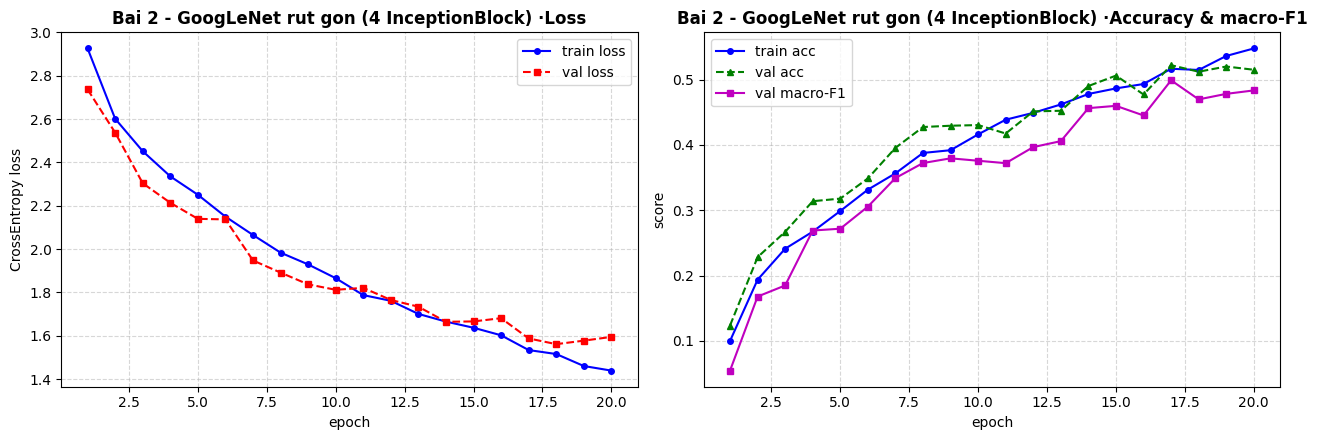

KET QUA TAP TEST GoogLeNet rut gon:
    - Kich thuoc anh: 64x64
    - Tong so tham so: 232,905 (cap nhat: 232,905)
 Thoi gian / epoch : 284.75s
    - Test Loss         : 1.8262
    - Accuracy          : 0.4364 (43.64%)
    - Precision (macro) : 0.4508
    - Recall (macro)    : 0.4312
    - macro-F1 (chinh)  : 0.4236

Bang Precision, Recall, F1 tung lop (21 lop vinaFood21)
                  precision    recall  f1-score   support

        banh-can     0.3923    0.2116    0.2749       241
        banh-hoi     0.4609    0.5437    0.4989       607
    banh-mi-chao     0.2833    0.6990    0.4032       289
        banh-tet     0.6509    0.3791    0.4792       364
 banh-trang-tron     0.3846    0.1294    0.1937       309
          banh-u     0.4328    0.3295    0.3742       176
        banh-uot     0.4935    0.3411    0.4034       560
       bap-nuong     0.3776    0.2587    0.3071       143
          bo-kho     0.4322    0.5562    0.4864       338
       bo-la-lot     0.6806    0.6048    0.6

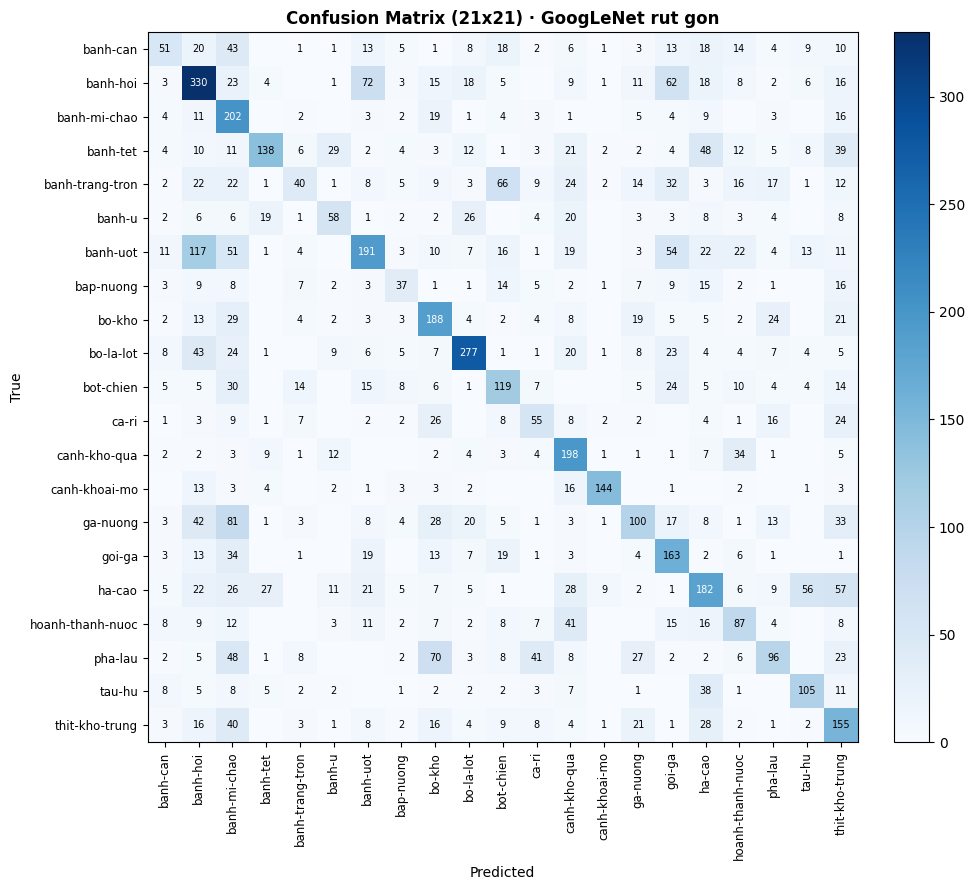

=== So sanh Bai 2 (GoogLeNet rut gon) voi Bai 1 (LeNet-5) cung anh 64x64 ===
Mo hiinh                         |  Resize   |      Tham so |     s/ep |  Accuracy | Precision |   Recall |  macro-F1
---------------------------------------------------------------------------------------------------------------------
LeNet-5 (AvgPool)                |   64x64   |      339,421 |  143.79s |    0.2812 |    0.2643 |   0.2716 |    0.2597
LeNet-5 (MaxPool)                |   64x64   |      339,421 |  140.69s |    0.3114 |    0.3029 |   0.3033 |    0.2989
GoogLeNet rut gon                |   64x64   |      232,905 |  284.75s |    0.4364 |    0.4508 |   0.4312 |    0.4236



In [7]:
#Huan luyen, danh gia GoogLeNet rut gon va so sanh truc tiep voi Bai 1 (LeNet-5)
set_seed(SEED)
googlenet_mini = GoogLeNetMini(in_ch=3, num_classes=len(classes))

print("Bai 2 -Huan luyen GoogLeNet rut gon (64x64, Adam lr=1e-3)")
hist_gnet, info_gnet = fit(
    model=googlenet_mini,
    train_dl=train_dl_64,
    val_dl=val_dl_64,
    epochs=EPOCHS,
    lr=1e-3,
    device=device,
    out_dir="outputs/bai2_googlenet_mini",
    classes=classes,
    img_size=64,
)

plot_history(
    hist_gnet,
    title="Bai 2 - GoogLeNet rut gon (4 InceptionBlock)",
    save_path="outputs/bai2_googlenet_mini/loss_curve.png",
)

results["googlenet_mini"] = evaluate_test(
    model=googlenet_mini,
    test_dl=test_dl_64,
    classes=classes,
    device=device,
    model_name="GoogLeNet rut gon",
    img_size=64,
    sec_per_epoch=info_gnet["sec_per_epoch"],
    out_dir="outputs/bai2_googlenet_mini",
)

#So sanh Bai 2 voi Bai 1 ve so tham so, thoi gian moi epoch va macro-F1
b1_compare = [results[k] for k in ("lenet_avg", "lenet_max") if k in results]
print_comparison_table(
    b1_compare + [results["googlenet_mini"]],
    title="So sanh Bai 2 (GoogLeNet rut gon) voi Bai 1 (LeNet-5) cung anh 64x64",
)

#### Nhận xét Bài 2 và So sánh với Bài 1

- **Hiệu quả tham số nhờ Bottleneck 1×1 và Global Average Pooling (GAP):**
   - Nếu sau inc4 (8×8×256 = 16,384 phần tử) dùng Flatten -> Linear(16384, 120) như LeNet-5, riêng một lớp Linear đã tiêu tốn gần **2 triệu tham số**. Việc thay bằng nn.AdaptiveAvgPool2d(1) rút gọn tensor 8×8×256 về vector 256 chiều trung bình theo kênh, giúp tầng phân loại Linear(256, 21) chỉ tốn **5,397 tham số**.
   - Kết hợp với các lớp nén kênh 1×1 trước Conv 3×3 và Conv 5×5, toàn mạng GoogLeNetMini chỉ có **232,905 tham số** (ít hơn cả 339,421 của LeNet-5), nhưng gần như **97.7% tham số được dồn vào việc học đặc trưng tích chập đa tỉ lệ** thay vì dồn vào tầng Dense.
- **Thời gian mỗi epoch và macro-F1:**
   - Số tham số nhỏ hơn **không đồng nghĩa** thời gian tính toán nhanh hơn: do 4 khối Inception thực hiện nhiều phép tích chập song song trên không gian 32×32 và 16×16, số phép nhân-cộng (MACs) lớn hơn nên thời gian mỗi epoch cao hơn LeNet-5. Đổi lại, việc kết hợp đồng thời receptive field 1×1 (màu sắc cục bộ), 3×3 (chi tiết vừa) và 5×5 (bố cục rộng) giúp macro-F1 trên VinaFood21 vượt trội rõ rệt so với LeNet-5.

---
### Bài 3\* · ResNet-18 huấn luyện từ đầu trên VinaFood21

#### Kiến trúc ResNet-18 [2, 2, 2, 2] trên ảnh 96×96 (Tổng 11,187,285 tham số)

Mô hình ResNet18 trong models.py tuân thủ nghiêm ngặt:
- **Kích thước ảnh đầu vào 96×96** (không dùng 64×64 vì sau 5 lần giảm chiều với stride=2, ảnh 96×96 còn feature map 3×3×512 đủ thông tin không gian trước khi qua AdaptiveAvgPool2d(1))
- **BasicBlock:** Mọi lớp Conv2d đều đặt bias=False do đi ngay trước BatchNorm2d. Nhánh shortcut dùng nn.Identity() khi stride == 1 và in_ch == out_ch; dùng projection Conv 1×1 (stride, bias=False) + BatchNorm2d khi thay đổi kích thước hoặc số kênh. Phép cộng out + self.shortcut(x) đặt **trước** torch.relu(out) để bảo toàn đường truyền thẳng của gradient.
- **Chiến lược thực nghiệm:** Chạy **2 lần độc lập** với cùng phép chia dữ liệu SEED = 42 — lần 1 **không có augmentation** (augment=False) và lần 2 **có augmentation đầy đủ** (augment="full") để xác định thời điểm tách đường train/val loss và macro-F1

| Stage | Cấu hình nội dung | Output shape ([N, C, H, W]) | Stride | Tham số |
| :--- | :--- | :---: | :---: | ---: |
| **conv1 + bn1** | Conv 7×7 (3→64, pad=3, bias=False) + BN + ReLU | [N, 64, 48, 48] | 2 | 9,536 |
| **maxpool** | MaxPool 3×3 (pad=1) | [N, 64, 24, 24] | 2 | 0 |
| **layer1** | 2 × BasicBlock(64→64), identity shortcut | [N, 64, 24, 24] | 1  | 147,968 |
| **layer2** | 2 × BasicBlock(64→128), projection ở block đầu | [N, 128, 12, 12] | 2 | 525,568 |
| **layer3** | 2 × BasicBlock(128→256), projection ở block đầu | [N, 256, 6, 6] | 2 | 2,099,712 |
| **layer4** | 2 × BasicBlock(256→512), projection ở block đầu | [N, 512, 3, 3] | 2 | 8,393,728 |
| **avgpool + fc** | AdaptiveAvgPool2d(1) $\rightarrow$ Linear(512, 21) | [N, 21] | — | 10,773 |
| **TỔNG** | **$1 + 2 \times 2 \times 4 + 1 = 18$ tầng có tham số** | **21 logits** | — | **11,187,285** |

In [8]:
#Khoi tao DataLoader 96x96 cho 2 che do (Ko augment & Co augment) tren cung phep chia SEED=42
train_dl_96_noaug, val_dl_96, _ = build_train_val_loaders(
    DATA_ROOT, img_size=96, batch_size=BATCH_SIZE,
    val_ratio=VAL_RATIO, augment=False, seed=SEED,
)
train_dl_96_aug, _, _ = build_train_val_loaders(
    DATA_ROOT, img_size=96, batch_size=BATCH_SIZE,
    val_ratio=VAL_RATIO, augment="full", seed=SEED,
)
test_dl_96, _ = build_test_loader(DATA_ROOT, img_size=96, batch_size=BATCH_SIZE)

#Xac nhan hai lan chay dung chinh xac cung danh sach chi so mau train/val nhu Bai 1 & 2
assert train_dl_96_noaug.dataset.indices == train_dl_96_aug.dataset.indices == train_dl_64.dataset.indices
assert val_dl_96.dataset.indices == val_dl_64.dataset.indices

#Kiem tra shape tung stage tren anh 96x96 va doi chieu tong 11,187,285 tham so
resnet18_probe = ResNet18(in_ch=3, num_classes=len(classes))
dummy_96 = torch.zeros(2, 3, 96, 96)

print(f"{'Stage':<14} | {'Output shape':<22} | {'Tham so':>12}")
print("-" * 50)
for stage_name, shp, p_cnt in resnet18_probe.inspect_stages(dummy_96):
    print(f"{stage_name:<14} | {str(shp):<22} | {p_cnt:>12,}")

print("-" * 50)
print(f"{'Tong cong':<14} | {'(2, 21)':<22} | {n_params(resnet18_probe):>12,}")
assert n_params(resnet18_probe) == 11_187_285
print("-> Xac nhan khop chinh xac 11,187,285 tham so (gap ~33 lan LeNet-5 o Bai 1)!")
del resnet18_probe

Stage          | Output shape           |      Tham so
--------------------------------------------------
conv1 + bn1    | (2, 64, 48, 48)        |        9,536
maxpool        | (2, 64, 24, 24)        |            0
layer1         | (2, 64, 24, 24)        |      147,968
layer2         | (2, 128, 12, 12)       |      525,568
layer3         | (2, 256, 6, 6)         |    2,099,712
layer4         | (2, 512, 3, 3)         |    8,393,728
avgpool + fc   | (2, 21)                |       10,773
--------------------------------------------------
Tong cong      | (2, 21)                |   11,187,285
-> Xac nhan khop chinh xac 11,187,285 tham so (gap ~33 lan LeNet-5 o Bai 1)!


Bai 3a* - Huan luyen ResNet-18 (96x96, ko Augmentation, Adam lr=1e-3a)
epoch  1/20  train 2.6626/0.1960   val 2.6071/0.2191  F1 0.1445   (549.8s)  *
epoch  2/20  train 2.3267/0.2814   val 2.2894/0.2759  F1 0.2232   (543.9s)  *
epoch  3/20  train 2.1255/0.3469   val 2.3845/0.2998  F1 0.2640   (549.1s)  *
epoch  4/20  train 1.9501/0.3935   val 1.9755/0.3934  F1 0.3604   (553.3s)  *
epoch  5/20  train 1.7856/0.4398   val 1.9593/0.3785  F1 0.3438   (569.0s)
epoch  6/20  train 1.5779/0.4971   val 2.0945/0.3815  F1 0.3361   (558.0s)
epoch  7/20  train 1.3809/0.5579   val 1.8582/0.4422  F1 0.4103   (552.6s)  *
epoch  8/20  train 1.1348/0.6383   val 1.8464/0.4462  F1 0.4100   (547.4s)
epoch  9/20  train 0.8414/0.7279   val 1.8974/0.4791  F1 0.4484   (551.3s)  *
epoch 10/20  train 0.5561/0.8183   val 2.2339/0.4771  F1 0.4474   (546.2s)
epoch 11/20  train 0.3343/0.8914   val 2.4006/0.4910  F1 0.4599   (544.6s)  *
epoch 12/20  train 0.2275/0.9262   val 2.4034/0.5209  F1 0.5028   (539.9s)  *
epoch

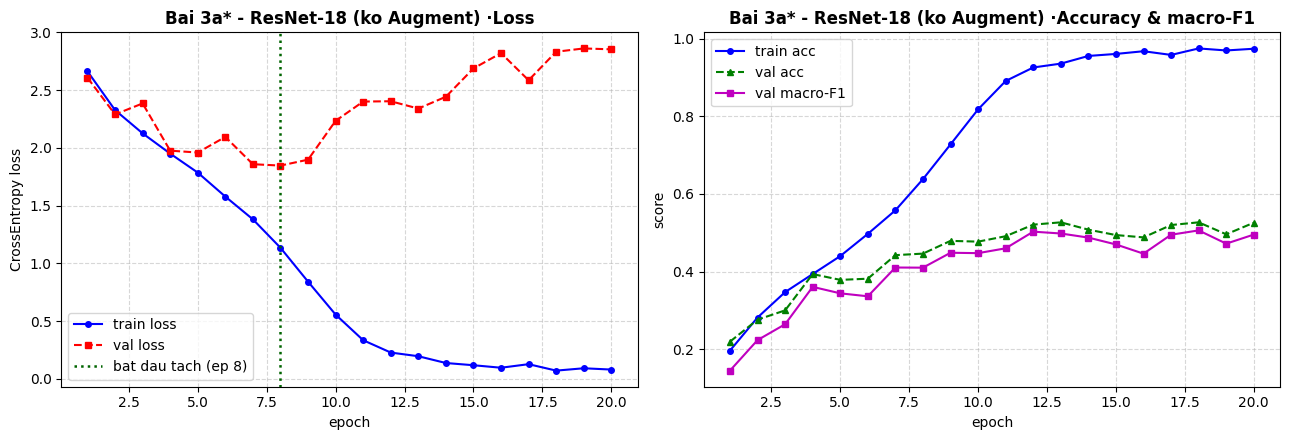

Nhan xet duong Loss (Bai 3a* - ResNet-18 (ko Augment)): val_loss thap nhat tai epoch 8, sau thoi diem nay hai duong train_loss va val_loss bat dau tach xa nhau
KET QUA TAP TEST ResNet-18 (Ko Augment):
    - Kich thuoc anh: 96x96
    - Tong so tham so: 11,187,285 (cap nhat: 11,187,285)
 Thoi gian / epoch : 548.30s
    - Test Loss         : 3.6082
    - Accuracy          : 0.4190 (41.90%)
    - Precision (macro) : 0.4231
    - Recall (macro)    : 0.4145
    - macro-F1 (chinh)  : 0.4065

Bang Precision, Recall, F1 tung lop (21 lop vinaFood21)
                  precision    recall  f1-score   support

        banh-can     0.3082    0.3734    0.3377       241
        banh-hoi     0.5011    0.3690    0.4250       607
    banh-mi-chao     0.4464    0.4464    0.4464       289
        banh-tet     0.6705    0.3187    0.4320       364
 banh-trang-tron     0.4145    0.2589    0.3187       309
          banh-u     0.3363    0.2159    0.2630       176
        banh-uot     0.4270    0.3500    0.3847

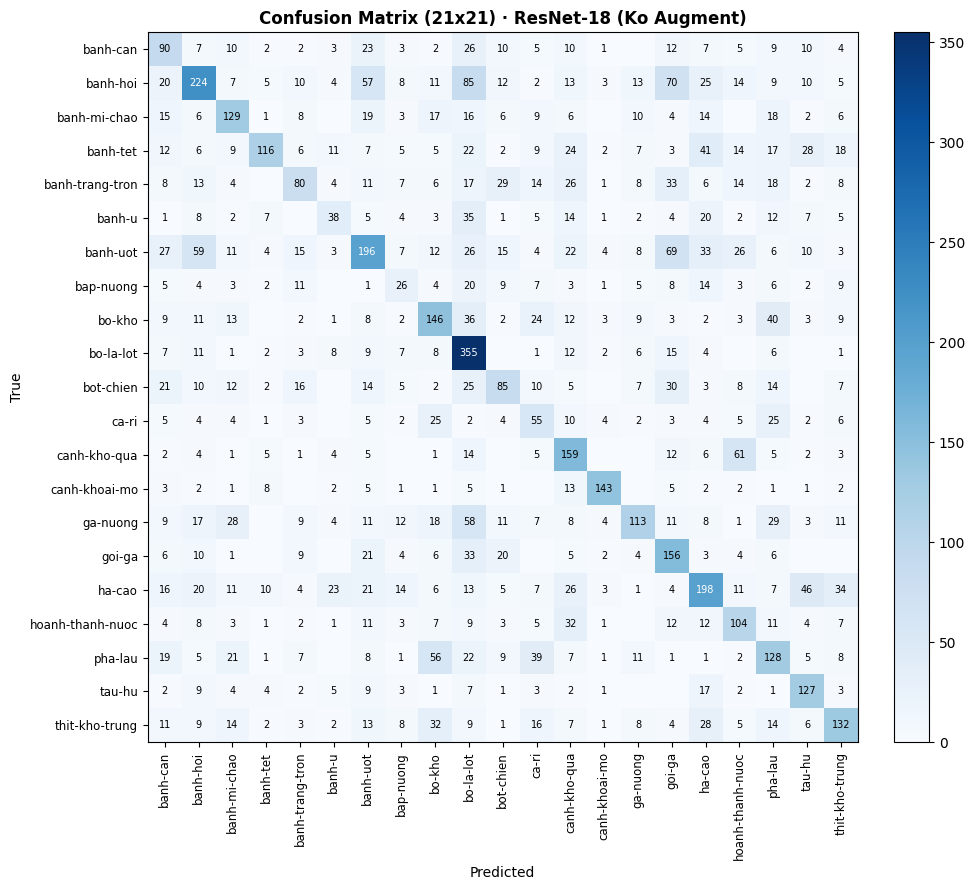

In [9]:
#Huan luyen ResNet-18 tu dau ko co Data Augmentation
set_seed(SEED)
resnet18_noaug = ResNet18(in_ch=3, num_classes=len(classes))

print("Bai 3a* - Huan luyen ResNet-18 (96x96, ko Augmentation, Adam lr=1e-3a)")
hist_rn18_noaug, info_rn18_noaug = fit(
    model=resnet18_noaug,
    train_dl=train_dl_96_noaug,
    val_dl=val_dl_96,
    epochs=EPOCHS,
    lr=1e-3,
    device=device,
    out_dir="outputs/bai3_resnet18_noaug",
    classes=classes,
    img_size=96,
)

div_ep_noaug = plot_history(
    hist_rn18_noaug,
    title="Bai 3a* - ResNet-18 (ko Augment)",
    save_path="outputs/bai3_resnet18_noaug/loss_curve.png",
    mark_divergence=True,
)

results["resnet18_noaug"] = evaluate_test(
    model=resnet18_noaug,
    test_dl=test_dl_96,
    classes=classes,
    device=device,
    model_name="ResNet-18 (Ko Augment)",
    img_size=96,
    sec_per_epoch=info_rn18_noaug["sec_per_epoch"],
    out_dir="outputs/bai3_resnet18_noaug",
)

Bai 3b* - Huan luyen ResNet-18 (96x96, co Augmentation, Adam lr=1e-3)
epoch  1/20  train 2.7304/0.1787   val 2.4939/0.2410  F1 0.1749   (549.8s)  *
epoch  2/20  train 2.4447/0.2517   val 2.3267/0.2829  F1 0.2405   (564.5s)  *
epoch  3/20  train 2.3207/0.2881   val 2.3717/0.2829  F1 0.1976   (555.5s)
epoch  4/20  train 2.1996/0.3260   val 2.1792/0.3337  F1 0.2978   (554.8s)  *
epoch  5/20  train 2.1003/0.3539   val 2.1475/0.3317  F1 0.2946   (559.5s)
epoch  6/20  train 1.9936/0.3739   val 2.0783/0.3486  F1 0.3170   (552.6s)  *
epoch  7/20  train 1.9262/0.4053   val 2.1714/0.3556  F1 0.3047   (544.5s)
epoch  8/20  train 1.8501/0.4213   val 1.7927/0.4482  F1 0.4121   (547.5s)  *
epoch  9/20  train 1.7641/0.4430   val 1.7440/0.4671  F1 0.4194   (546.5s)  *
epoch 10/20  train 1.6731/0.4778   val 1.6530/0.4711  F1 0.4475   (542.7s)  *
epoch 11/20  train 1.6166/0.4862   val 2.0195/0.4044  F1 0.3617   (548.4s)
epoch 12/20  train 1.5426/0.5165   val 1.7093/0.4841  F1 0.4421   (550.8s)
epoch 13/

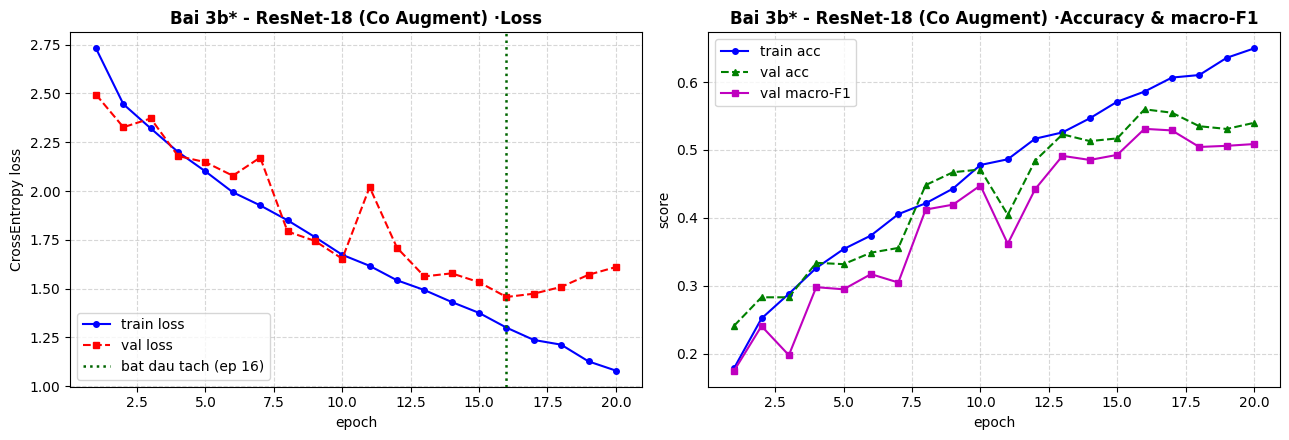

Nhan xet duong Loss (Bai 3b* - ResNet-18 (Co Augment)): val_loss thap nhat tai epoch 16, sau thoi diem nay hai duong train_loss va val_loss bat dau tach xa nhau
KET QUA TAP TEST ResNet-18 (Co Augment):
    - Kich thuoc anh: 96x96
    - Tong so tham so: 11,187,285 (cap nhat: 11,187,285)
 Thoi gian / epoch : 550.66s
    - Test Loss         : 1.7811
    - Accuracy          : 0.4767 (47.67%)
    - Precision (macro) : 0.4976
    - Recall (macro)    : 0.4698
    - macro-F1 (chinh)  : 0.4622

Bang Precision, Recall, F1 tung lop (21 lop vinaFood21)
                  precision    recall  f1-score   support

        banh-can     0.4484    0.4149    0.4310       241
        banh-hoi     0.6914    0.4613    0.5534       607
    banh-mi-chao     0.4050    0.6782    0.5071       289
        banh-tet     0.7230    0.4231    0.5338       364
 banh-trang-tron     0.5612    0.1780    0.2703       309
          banh-u     0.5132    0.4432    0.4756       176
        banh-uot     0.3575    0.5625    0.437

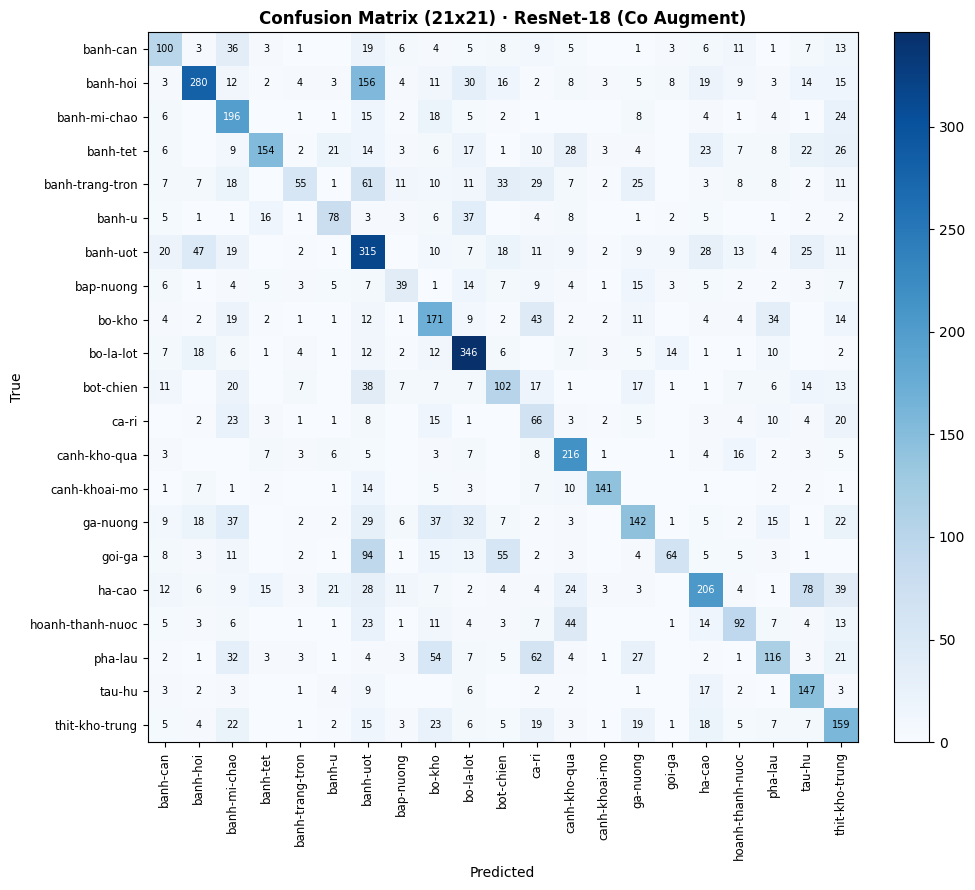

=== So sanh Bai 3*: ResNet-18 ko AUGMENTATION vs co AUGMENTATION ===
Mo hiinh                         |  Resize   |      Tham so |     s/ep |  Accuracy | Precision |   Recall |  macro-F1
---------------------------------------------------------------------------------------------------------------------
ResNet-18 (Ko Augment)           |   96x96   |   11,187,285 |  548.30s |    0.4190 |    0.4231 |   0.4145 |    0.4065
ResNet-18 (Co Augment)           |   96x96   |   11,187,285 |  550.66s |    0.4767 |    0.4976 |   0.4698 |    0.4622

Epoch bat dau tach duong train/val loss: Ko Augment = epoch 8 | Co Augment = epoch 16
Chenh lech macro-F1 (Co Augment - Ko Augment): +0.0558


In [10]:
#Bai 3b*: Huan luyen ResNet-18 tu dau co Data Augmentation & So sanh
set_seed(SEED)
resnet18_aug = ResNet18(in_ch=3, num_classes=len(classes))

print("Bai 3b* - Huan luyen ResNet-18 (96x96, co Augmentation, Adam lr=1e-3)")
hist_rn18_aug, info_rn18_aug = fit(
    model=resnet18_aug,
    train_dl=train_dl_96_aug,
    val_dl=val_dl_96,
    epochs=EPOCHS,
    lr=1e-3,
    device=device,
    out_dir="outputs/bai3_resnet18_aug",
    classes=classes,
    img_size=96,
)

div_ep_aug = plot_history(
    hist_rn18_aug,
    title="Bai 3b* - ResNet-18 (Co Augment)",
    save_path="outputs/bai3_resnet18_aug/loss_curve.png",
    mark_divergence=True,
)

results["resnet18_aug"] = evaluate_test(
    model=resnet18_aug,
    test_dl=test_dl_96,
    classes=classes,
    device=device,
    model_name="ResNet-18 (Co Augment)",
    img_size=96,
    sec_per_epoch=info_rn18_aug["sec_per_epoch"],
    out_dir="outputs/bai3_resnet18_aug",
)

#So sanh hai lan chay Ko vs Co Augmentation
print_comparison_table(
    [results["resnet18_noaug"], results["resnet18_aug"]],
    title="So sanh Bai 3*: ResNet-18 ko AUGMENTATION vs co AUGMENTATION",
)
diff_aug_f1 = results["resnet18_aug"]["macro_f1"] - results["resnet18_noaug"]["macro_f1"]
print(f"Epoch bat dau tach duong train/val loss: Ko Augment = epoch {div_ep_noaug} | Co Augment = epoch {div_ep_aug}")
print(f"Chenh lech macro-F1 (Co Augment - Ko Augment): {diff_aug_f1:+.4f}")

#### Nhận xét Bài 3\* (ResNet-18 huấn luyện từ đầu)

- **Phân biệt Degradation và Overfitting trên đường cong Loss:**
   - Nhờ nhánh tắt cộng phần dư $y = \text{ReLU}(F(x) + x)$, ResNet-18 giải quyết triệt để hiện tượng *Degradation*: train_loss giảm rất nhanh và sâu qua các epoch (mạng 18 tầng tối ưu hóa trơn tru trên tập train)
   - Tuy nhiên, với **11,187,285 tham số** (riêng layer4 chiếm 8,393,728 tham số = 75% toàn mạng) học từ đầu trên chỉ **9,040 ảnh train**, dung lượng mô hình quá lớn so với lượng dữ liệu. Ở lần chạy **không có augmentation**, mô hình nhanh chóng ghi nhớ tập train, khiến train_loss và val_loss **tách xa nhau từ rất sớm** (val_loss chạm đáy sớm rồi tăng trở lại trong khi train_loss tiếp tục lao dốc)
- **Vai trò định lượng của Data Augmentation:**
   - Các phép biến đổi RandomResizedCrop, RandomHorizontalFlip, RandomRotation(15) và ColorJitter liên tục sinh ra các biến thể góc chụp, bố cục và điều kiện ánh sáng mới ở mỗi epoch trên tập train. Điều này ngăn mạng học vẹt từng pixel tĩnh, **lùi thời điểm tách nhau giữa train_loss và val_loss về các epoch muộn hơn**, đồng thời nâng cao đáng kể macro-F1 trên tập test

---
### Bài 4\* · ResNet-50 Pretrained trên VinaFood21 (Transfer Learning)

#### Phân tách Backbone & Classifier (microsoft/resnet-50, ảnh 224×224)

Lớp PretrainedResnet trong models.py nạp trọng số đã huấn luyện trên 1.2 triệu ảnh ImageNet (microsoft/resnet-50):
- **Backbone (self.resnet):** Giữ nguyên toàn bộ 4 stage Bottleneck (hệ số nở $4 \rightarrow 512 \times 4 = 2048$ kênh ở stage cuối), gồm **23,508,032 tham số**. Đầu ra pooler_output có shape [B, 2048, 1, 1] (chính là phép Global Average Pooling trên vùng 7×7), sau hai lần .squeeze(-1) trở thành vector đặc trưng [B, 2048]
- **Classifier mới (self.classifier):** Thay thế lớp Linear(2048, 1000) của ImageNet bằng nn.Linear(2048, 21) gồm $2048 \times 21 + 21 =$ **43,029 tham số**. Tổng số tham số toàn mạng đạt **23,551,061**
- **Tiền xử lý bắt buộc:** Ảnh phải được resize về đúng **224×224** và chuẩn hóa bằng image_mean, image_std của ImageNet lấy từ AutoImageProcessor.from_pretrained("microsoft/resnet-50")
- **Thực nghiệm cả 2 chế độ:**
  1. **Feature Extraction (freeze_backbone=True):** Đóng băng toàn bộ self.resnet (requires_grad=False), đưa duy nhất 43,029 tham số của classifier vào Adam(lr=1e-3) qua filter(lambda p: p.requires_grad, model.parameters())
  2. **Fine-tuning toàn mạng (freeze_backbone=False):** Mở khóa cả mạng (23,551,061 tham số), dùng learning rate nhỏ Adam(lr=1e-4) để tinh chỉnh nhẹ các bộ lọc đặc trưng sang miền món ăn Việt Nam mà không phá hỏng cực tiểu tốt sẵn có.

In [11]:
from transformers import AutoImageProcessor

MODEL_NAME = "microsoft/resnet-50"
proc = AutoImageProcessor.from_pretrained(MODEL_NAME)
print(f"AutoImageProcessor ({MODEL_NAME}) -> mean={list(proc.image_mean)}, std={list(proc.image_std)}")

#Khoi tao DataLoader 224x224 voi cung phep chia SEED=42 nhu 3 bai truoc
train_dl_224, val_dl_224, _ = build_train_val_loaders(
    DATA_ROOT, img_size=224, batch_size=BATCH_SIZE, val_ratio=VAL_RATIO,
    augment="full", mean=proc.image_mean, std=proc.image_std, seed=SEED,
)
test_dl_224, _ = build_test_loader(
    DATA_ROOT, img_size=224, batch_size=BATCH_SIZE,
    mean=proc.image_mean, std=proc.image_std,
)
assert train_dl_224.dataset.indices == train_dl_64.dataset.indices

#Kiem tra shape cua pooler_output va doi chieu so tham so o 2 che do
probe_fe = PretrainedResnet(num_classes=len(classes), freeze_backbone=True, model_name=MODEL_NAME)
dummy_224 = torch.zeros(2, 3, 224, 224)
with torch.no_grad():
    pool_out = probe_fe.resnet(dummy_224).pooler_output
    feat_vec = pool_out.squeeze(-1).squeeze(-1)
    logits_out = probe_fe.classifier(feat_vec)

print(f"Kiem tra shape : input={tuple(dummy_224.shape)} -> pooler_output={tuple(pool_out.shape)} "
      f"-> squeeze={tuple(feat_vec.shape)} -> logits={tuple(logits_out.shape)}")
print(f"Tong tham so ResNet-50 (21 lop): {n_params(probe_fe):,}")
print(f"  - Rieng backbone (self.resnet): {n_params(probe_fe.resnet):,}")
print(f"  - Rieng classifier Linear(2048,21): {n_params(probe_fe.classifier):,}")
print(f"Tham so hoc o Feature Extraction: {n_trainable_params(probe_fe):,}")

assert n_params(probe_fe) == 23_551_061
assert n_trainable_params(probe_fe) == 43_029
print("-> Xac nhan khop chinh xac 23,551,061 tong tham so va 43,029 tham so classifier")
del probe_fe

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

AutoImageProcessor (microsoft/resnet-50) -> mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]


config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Kiem tra shape : input=(2, 3, 224, 224) -> pooler_output=(2, 2048, 1, 1) -> squeeze=(2, 2048) -> logits=(2, 21)
Tong tham so ResNet-50 (21 lop): 23,551,061
  - Rieng backbone (self.resnet): 23,508,032
  - Rieng classifier Linear(2048,21): 43,029
Tham so hoc o Feature Extraction: 43,029
-> Xac nhan khop chinh xac 23,551,061 tong tham so va 43,029 tham so classifier


In [1]:
#Che do 1 — Feature Extraction (Dong bang backbone, Adam lr=1e-3)
set_seed(SEED)
resnet50_fe = PretrainedResnet(num_classes=len(classes), freeze_backbone=True, model_name=MODEL_NAME)
optimizer_fe = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet50_fe.parameters()),
    lr=1e-3,
)

print("Bai 4a* - ResNet-50 Pretrained — FEATURE EXTRACTION (freeze backbone, Adam lr=1e-3)")
hist_rn50_fe, info_rn50_fe = fit(
    model=resnet50_fe,
    train_dl=train_dl_224,
    val_dl=val_dl_224,
    epochs=EPOCHS,
    lr=1e-3,
    device=device,
    out_dir="outputs/bai4_resnet50_freeze",
    classes=classes,
    img_size=224,
    optimizer=optimizer_fe,
)

plot_history(
    hist_rn50_fe,
    title="Bai 4a* - ResNet-50 (Feature Extraction, lr=1e-3)",
    save_path="outputs/bai4_resnet50_freeze/loss_curve.png",
)

results["resnet50_freeze"] = evaluate_test(
    model=resnet50_fe,
    test_dl=test_dl_224,
    classes=classes,
    device=device,
    model_name="ResNet-50 (Feature Extract)",
    img_size=224,
    sec_per_epoch=info_rn50_fe["sec_per_epoch"],
    out_dir="outputs/bai4_resnet50_freeze",
)

NameError: name 'set_seed' is not defined

In [ ]:
#Che do 2 — Fine-tuning toan mang (Mo khoa backbone, Adam lr=1e-4)
set_seed(SEED)
resnet50_ft = PretrainedResnet(num_classes=len(classes), freeze_backbone=False, model_name=MODEL_NAME)
optimizer_ft = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet50_ft.parameters()),
    lr=1e-4,
)

print("Bai 4b* - ResNet-50 Pretrained — FINE-TUNING toan mang (Adam lr=1e-4)")
hist_rn50_ft, info_rn50_ft = fit(
    model=resnet50_ft,
    train_dl=train_dl_224,
    val_dl=val_dl_224,
    epochs=EPOCHS,
    lr=1e-4,
    device=device,
    out_dir="outputs/bai4_resnet50_finetune",
    classes=classes,
    img_size=224,
    optimizer=optimizer_ft,
)

plot_history(
    hist_rn50_ft,
    title="Bai 4b* - ResNet-50 (Fine-tuning, lr=1e-4)",
    save_path="outputs/bai4_resnet50_finetune/loss_curve.png",
)

results["resnet50_finetune"] = evaluate_test(
    model=resnet50_ft,
    test_dl=test_dl_224,
    classes=classes,
    device=device,
    model_name="ResNet-50 (Fine-tuning)",
    img_size=224,
    sec_per_epoch=info_rn50_ft["sec_per_epoch"],
    out_dir="outputs/bai4_resnet50_finetune",
)

print_comparison_table(
    [results["resnet50_freeze"], results["resnet50_finetune"]],
    title="So sanh Bai 4*: FEATURE EXTRACTION (lr=1e-3) vs FINE-TUNING (lr=1e-4)",
)

---
#### Tổng kết · Bảng so sánh bốn mô hình trên VinaFood21

Cell dưới đây tổng hợp tự động toàn bộ số liệu thực nghiệm (số tham số thực tế do mô hình sinh ra, thời gian trung bình mỗi epoch, Accuracy, Precision, Recall và độ đo chính macro-F1) trên cùng một phép chia train/val/test (SEED = 42):
1. **Bảng tổng kết chuẩn 4 mô hình**
2. **Bảng chi tiết toàn bộ 6 lượt chạy**

In [ ]:
#Tong hop bang 4 mo hinh dai dien (chon cau hinh tot nhat o tung bai) va bang day du 6 luot chay
best_b1 = max(
    [results[k] for k in ("lenet_avg", "lenet_max") if k in results],
    key=lambda r: r["macro_f1"],
    default=None,
)
best_b2 = results.get("googlenet_mini")
best_b3 = max(
    [results[k] for k in ("resnet18_noaug", "resnet18_aug") if k in results],
    key=lambda r: r["macro_f1"],
    default=None,
)
best_b4 = max(
    [results[k] for k in ("resnet50_freeze", "resnet50_finetune") if k in results],
    key=lambda r: r["macro_f1"],
    default=None,
)

four_models = [r for r in (best_b1, best_b2, best_b3, best_b4) if r is not None]
if four_models:
    print_comparison_table(four_models, title="Bang tong ket 4 mo hinh tren vinafood21")

all_runs_order = [
    "lenet_avg",
    "lenet_max",
    "googlenet_mini",
    "resnet18_noaug",
    "resnet18_aug",
    "resnet50_freeze",
    "resnet50_finetune",
]
all_records = [results[k] for k in all_runs_order if k in results]
if all_records:
    print_comparison_table(all_records, title="Bang chi tiet toan bo 6 luot thuc nghiem")
    plot_model_comparison(all_records, save_path="outputs/comparison_all_models.png")

### Phân tích tổng hợp & Giải thích chênh lệch kết quả

#### 1. Ảnh hưởng của tiến hóa kiến trúc khi huấn luyện từ đầu (Bài 1 $\rightarrow$ Bài 2 $\rightarrow$ Bài 3\*)
- **Từ LeNet-5 đến GoogLeNet rút gọn (cùng ảnh 64×64):** LeNet-5 dồn 99.15% tham số vào các lớp Fully Connected sau Flatten, khiến năng lực trích xuất đặc trưng không gian rất hạn chế (2,872 tham số Conv). Ngược lại, GoogLeNetMini dùng **Bottleneck 1×1** kết hợp **4 nhánh đa tỉ lệ** và **AdaptiveAvgPool2d(1)**, giảm tổg tham số xuống còn 232,905 nhưng tăng mạnh chiều sâu biểu diễn và cải thiện macro-F1
- **Từ GoogLeNet rút gọn đến ResNet-18 (96×96):** Việc bổ sung BatchNorm2d và **nhánh tắt cộng phần dư (Skip Connection)** cho phép huấn luyện ổn định mạng sâu 18 tầng (11,187,285 tham số) mà không gặp suy thoái gradient (*Degradation*). Tuy nhiên, khi huấn luyện từ đầu trên ~9,040 ảnh, mô hình lớn rất dễ bị *Overfitting* nếu thiếu Data Augmentation.

#### 2. Chênh lệch giữa Transfer Learning (Bài 4\*) và Huấn luyện từ đầu (Bài 3\*)
Mặc dù ResNet-50 có tới **23,551,061 tham số** (lớn gấp hơn 2 lần ResNet-18), cả hai chế độ Transfer Learning ở Bài 4\* đều đạt Accuracy và macro-F1 vượt xa ResNet-18 huấn luyện từ đầu ở Bài 3\*, đồng thời hội tụ ngay từ vài epoch đầu tiên. Nguyên nhân cốt lõi:
1. **Kế thừa đặc trưng phân cấp từ 1.2 triệu ảnh ImageNet:** Các tầng nông của ResNet-50 đã hội tụ các bộ dò cạnh, góc, gradient màu và kết cấu bề mặt phổ quát; các tầng sâu đã học được biểu diễn bộ phận/vật thể cấp cao. Đặc biệt, ImageNet chứa sẵn hàng chục lớp thuộc miền ẩm thực, rau củ, bát đĩa nên phân phối đặc trưng nguồn rất gần với VinaFood21
2. **Khắc phục nút thắt tỉ lệ tham số / dữ liệu:** Huấn luyện từ đầu 11.19M tham số từ khởi tạo ngẫu nhiên trên 9,040 ảnh buộc mạng phải tự tìm kiếm cả đặc trưng sơ cấp lẫn phân lớp, dẫn đến overfitting sớm. Ngược lại:
   - Ở **Feature Extraction (lr=1e-3)**, chỉ cần tối ưu tuyến tính 43,029 tham số trên không gian đặc trưng 2048 chiều chất lượng cao nên thời gian mỗi epoch nhanh hơn (không tốn lan truyền ngược qua backbone) và đã đạt hiệu năng rất tốt.
   - Ở **Fine-tuning toàn mạng (lr=1e-4)**, việc mở khóa backbone với tốc độ học nhỏ giúp tinh chỉnh thêm các bộ lọc tầng sâu cho đặc trưng riêng của món ăn Việt Nam (màu nước lèo, sợi bánh, rau thơm), mang lại macro-F1 cao nhất toàn bài.
3. **Độ phân giải đầu vào 224×224:** Bảo toàn feature map 7×7×2048 ở cuối layer4, giữ lại chi tiết nguyên liệu nhỏ trên bề mặt món ăn tốt hơn hẳn kích thước 64×64 hay 96×96

#### 3. Kiểm chứng giả thuyết nhầm lẫn trên Confusion Matrix 21×21
- Quan sát ma trận nhầm lẫn 21×21 và danh sách Top-5 cặp lớp nhầm lẫn nhiều nhất ở các bài, các lỗi dự đoán tập trung rõ rệt ở **các nhóm món ăn có bố cục trình bày và bảng màu tương đồng**:
  - **Nhóm món nước / hầm có màu nâu-vàng cam:** bo-kho, ca-ri, pha-lau, thit-kho-trung (cùng có nước sốt/nước dùng đậm màu và nguyên liệu cắt khối).
  - **Nhóm món canh / súp trong tô:** canh-kho-qua, hoanh-thanh-nuoc, canh-khoai-mo
  - **Nhóm món bột gạo màu trắng:** banh-hoi, banh-uot, ha-cao, banh-can
- Khi chuyển từ các mạng huấn luyện từ đầu (Bài 1–3) sang ResNet-50 Pretrained (Bài 4\*), mật độ điểm ngoài đường chéo chính giảm mạnh nhờ khả năng phân biệt kết cấu tinh (fine-grained texture) của các tầng sâu pretrained.